# Re-identification (linkage attack) on `anonymised_dataC.csv`

**Goal:** link as many records as possible in the anonymised file back to named people in `respondents_tableC.csv`.

**Plan**
1. Find which columns the two files share (the *quasi-identifiers*).
2. Test for a row-order leak.
3. Group records into equivalence classes and measure uniqueness (k-anonymity).
4. Linkage attack: candidate sets, expected number of correct re-identifications.
5. Attribute-disclosure attack: infer the sensitive attribute (`party`) for named people.
6. Risk metrics (prosecutor / journalist / marketer, l-diversity, t-closeness).
7. Hook to rerun everything if you obtain extra auxiliary data.

Outputs: `reidentification_candidates.csv` and `attribute_inference.csv`.

In [5]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)

anon = pd.read_csv(r"../dataC/anonymised_dataC.csv")
resp = pd.read_csv(r"../dataC/respondents_tableC.csv")
anon["anon_id"] = anon.index          # row number in the anonymised file (no real ID exists)
print(anon.shape, resp.shape)
display(anon.head()); display(resp.head())

(200, 6) (200, 9)


,sex,age_group,education,evote,party,anon_id
0,Female,60+,1 Primary,0,Red,0
1,Male,20-39,2 Upper secondary/VET,0,Green,1
2,Female,40-59,3 Short/medium higher,0,Red,2
3,Male,20-39,2 Upper secondary/VET,0,Green,3
4,Male,20-39,2 Upper secondary/VET,0,Green,4


,name,sex,dob,age,age_group,evote,zip,citizenship,marital_status
0,"Mcnally, Kyrie",Female,1975-04-27,50,40-59,0,2200,Denmark,Never married
1,"Meraz, Krista",Female,1980-04-29,45,40-59,0,2400,Denmark,Married/separated
2,"al-Rizk, Zainuddeen",Male,1985-10-26,39,20-39,0,2300,Denmark,Married/separated
3,"Powers, Hannah",Female,1959-03-11,66,60+,0,2400,Denmark,Widowed
4,"Thompson, Sarah",Female,1999-04-18,26,20-39,0,2200,Denmark,Never married


## 1. Shared columns = quasi-identifiers

In [6]:
QI = [c for c in anon.columns if c in resp.columns and c != "anon_id"]
print("Shared columns:", QI)
for c in QI:
    print(c, "| anon:", sorted(anon[c].unique()), "| resp:", sorted(resp[c].unique()))

Shared columns: ['sex', 'age_group', 'evote']
sex | anon: ['Female', 'Male'] | resp: ['Female', 'Male']
age_group | anon: ['20-39', '40-59', '60+'] | resp: ['20-39', '40-59', '60+']
evote | anon: [np.int64(0), np.int64(1)] | resp: [np.int64(0), np.int64(1)]


Only `sex`, `age_group` and `evote` overlap. The anonymised file additionally holds `education` and `party`
(never present in the respondents table), and the respondents table holds `name`, `dob`, `zip`, `citizenship`, `marital_status`
(never present in the anonymised file). The attack therefore links on the 3 shared columns and the payoff is learning `party`/`education` for named people.

## 2. Row-order leak test
If both files were exported in the same order, row *i* would match row *i* far more often than chance.

In [7]:
same = (anon[QI].values == resp[QI].values).all(axis=1).mean()
# expected agreement if rows were unrelated
p = (anon.groupby(QI).size() / len(anon)) * (resp.groupby(QI).size() / len(resp))
print(f"Row-aligned QI agreement: {same:.3f}  vs. chance level {p.sum():.3f}")
print("-> row order leaks" if same > p.sum() + 0.15 else "-> no row-order leak (shuffled)")

Row-aligned QI agreement: 0.085  vs. chance level 0.108
-> no row-order leak (shuffled)


## 3. Equivalence classes and uniqueness

n_anon  n_resp
sex    age_group evote                
Female 20-39     0          17      17
                 1           9       9
       40-59     0          34      34
                 1           7       7
       60+       0          20      20
                 1           5       5
Male   20-39     0          20      20
                 1          12      12
       40-59     0          30      30
                 1          15      15
       60+       0          25      25
                 1           6       6

Classes: 12 | smallest class k = 5 | unique records (k=1): 0


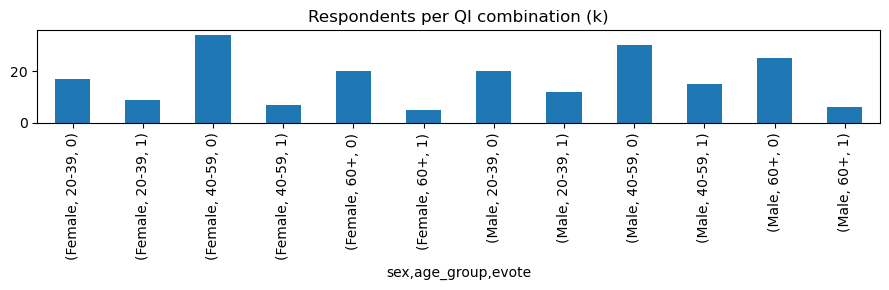

In [8]:
def classes(qi):
    a = anon.groupby(qi).size().rename("n_anon")
    r = resp.groupby(qi).size().rename("n_resp")
    return pd.concat([a, r], axis=1).fillna(0).astype(int)

cls = classes(QI)
display(cls)
print("Classes:", len(cls), "| smallest class k =", cls.n_resp.min(), "| unique records (k=1):", int((cls.n_resp == 1).sum()))
cls.n_resp.plot.bar(figsize=(9, 3), title="Respondents per QI combination (k)"); plt.tight_layout(); plt.show()

## 4. Linkage attack

In [9]:
def linkage(qi):
    cand = anon.merge(resp, on=qi, how="left", suffixes=("", "_r"))
    k = cand.groupby("anon_id").size().rename("k")
    names = cand.groupby("anon_id")["name"].apply(list).rename("candidates")
    out = anon.join(k, on="anon_id").join(names, on="anon_id")
    out["confidence"] = 1 / out["k"]
    return out

link = linkage(QI)
print("Exactly re-identified (k = 1):", int((link.k == 1).sum()), "of", len(link))
print("Narrowed to <= 5 candidates :", int((link.k <= 5).sum()))
print("Expected correct if guessing uniformly inside each class:", round(link.confidence.sum(), 1),
      f"({link.confidence.sum()/len(link):.1%})")
print("Median candidate set size:", link.k.median())

Exactly re-identified (k = 1): 0 of 200
Narrowed to <= 5 candidates : 5
Expected correct if guessing uniformly inside each class: 12.0 (6.0%)
Median candidate set size: 20.0


In [10]:
# Monte-Carlo check: truth = random pairing inside each class, attacker also guesses a random pairing inside the class
rng = np.random.default_rng(0)
sizes = cls.n_resp.values
hits = [sum((rng.permutation(n) == rng.permutation(n)).sum() for n in sizes) for _ in range(5000)]
print(f"Simulated correct re-identifications: {np.mean(hits):.1f} of {len(anon)} (analytic: {len(cls)})")

Simulated correct re-identifications: 12.0 of 200 (analytic: 12)


With these three quasi-identifiers every class contains **at least 5 people**, so no record can be *exactly* identified.
The best any attacker can do is narrow each record to a short candidate list. The table below is the 'answer sheet'.

In [11]:
link["candidate_names"] = link.candidates.apply(lambda l: "; ".join(l))
out = link[["anon_id"] + QI + ["education", "party", "k", "confidence", "candidate_names"]]
out.to_csv("reidentification_candidates.csv", index=False)
display(out.sort_values("k").head(15))

,anon_id,sex,age_group,evote,education,party,k,confidence,candidate_names
41,41,Female,60+,1,3 Short/medium higher,Invalid vote,5,0.200000,"al-Amber, Siddeeqa; Kee, Julia; Vukelich, Ava;..."
57,57,Female,60+,1,4 Long higher (Master/PhD),Red,5,0.200000,"al-Amber, Siddeeqa; Kee, Julia; Vukelich, Ava;..."
196,196,Female,60+,1,2 Upper secondary/VET,Green,5,0.200000,"al-Amber, Siddeeqa; Kee, Julia; Vukelich, Ava;..."
21,21,Female,60+,1,2 Upper secondary/VET,Red,5,0.200000,"al-Amber, Siddeeqa; Kee, Julia; Vukelich, Ava;..."
12,12,Female,60+,1,2 Upper secondary/VET,Red,5,0.200000,"al-Amber, Siddeeqa; Kee, Julia; Vukelich, Ava;..."
172,172,Male,60+,1,3 Short/medium higher,Red,6,0.166667,"Welch, Donovan; Gourd, Nicholas; Machisa, Lade..."
75,75,Male,60+,1,3 Short/medium higher,Green,6,0.166667,"Welch, Donovan; Gourd, Nicholas; Machisa, Lade..."
82,82,Male,60+,1,3 Short/medium higher,Red,6,0.166667,"Welch, Donovan; Gourd, Nicholas; Machisa, Lade..."
17,17,Male,60+,1,2 Upper secondary/VET,Green,6,0.166667,"Welch, Donovan; Gourd, Nicholas; Machisa, Lade..."
138,138,Male,60+,1,1 Primary,Green,6,0.166667,"Welch, Donovan; Gourd, Nicholas; Machisa, Lade..."


## 5. Attribute-disclosure attack (where the real leakage is)
Even when identity is ambiguous, if people in a class mostly share a sensitive value you learn it for *everyone* in that class.
For each respondent we use the class distribution of `party` as the posterior and guess the most likely value.

In [12]:
post = pd.crosstab([anon[c] for c in QI], anon.party, normalize="index")
counts = pd.crosstab([anon[c] for c in QI], anon.party)
display(counts.assign(total=counts.sum(axis=1), majority=post.idxmax(axis=1), confidence=post.max(axis=1).round(2)))

acc_attack   = counts.max(axis=1).sum() / len(anon)
acc_baseline = anon.party.value_counts(normalize=True).max()
print(f"Attack accuracy (class-majority party): {acc_attack:.1%}")
print(f"Baseline (always guess '{anon.party.value_counts().idxmax()}'): {acc_baseline:.1%}")

party                   Green  Invalid vote  Red  total majority  confidence
sex    age_group evote                                                      
Female 20-39     0         12             0    5     17    Green        0.71
                 1          7             0    2      9    Green        0.78
       40-59     0         20             0   14     34    Green        0.59
                 1          5             0    2      7    Green        0.71
       60+       0          6             1   13     20      Red        0.65
                 1          1             1    3      5      Red        0.60
Male   20-39     0         18             1    1     20    Green        0.90
                 1         10             0    2     12    Green        0.83
       40-59     0         21             0    9     30    Green        0.70
                 1          8             1    6     15    Green        0.53
       60+       0         15             0   10     25    Green        0.60
                 1          3             0    3      6    Green        0.50

Attack accuracy (class-majority party): 67.5%
Baseline (always guess 'Green'): 63.0%


In [18]:
inf = resp[["name"] + QI].merge(post.reset_index(), on=QI)
inf["inferred_party"] = inf[["Green", "Invalid vote", "Red"]].idxmax(axis=1)
inf["confidence"] = inf[["Green", "Invalid vote", "Red"]].max(axis=1).round(3)
inf.to_csv("attribute_inference.csv", index=False)
print("Named people with inferred party confidence >= 70%:", int((inf.confidence >= .70).sum()), "of", len(inf))
display(inf.sort_values("confidence", ascending=False).head(50))

Named people with inferred party confidence >= 70%: 95 of 200


,name,sex,age_group,evote,Green,Invalid vote,Red,inferred_party,confidence
191,"Carter, Matthew",Male,20-39,0,0.900000,0.05,0.050000,Green,0.900
75,"Pabalan, Daniel",Male,20-39,0,0.900000,0.05,0.050000,Green,0.900
162,"Clark, Tyler",Male,20-39,0,0.900000,0.05,0.050000,Green,0.900
158,"Valdez, Ismael",Male,20-39,0,0.900000,0.05,0.050000,Green,0.900
110,"Moon, Heli",Male,20-39,0,0.900000,0.05,0.050000,Green,0.900
124,"Cheatham, Tevin",Male,20-39,0,0.900000,0.05,0.050000,Green,0.900
17,"Wang, Vinh",Male,20-39,0,0.900000,0.05,0.050000,Green,0.900
15,"Cordiner, Darren",Male,20-39,0,0.900000,0.05,0.050000,Green,0.900
14,"Leidig, Jeffrey",Male,20-39,0,0.900000,0.05,0.050000,Green,0.900
193,"Watkins, Ryan",Male,20-39,0,0.900000,0.05,0.050000,Green,0.900


## 6. Risk metrics

In [19]:
k = link.k
print(f"Prosecutor risk (max 1/k)   : {1/k.min():.2%}")
print(f"Average prosecutor risk     : {(1/k).mean():.2%}")
print(f"Marketer risk (exp. % re-id): {(1/k).sum()/len(k):.2%}")
print(f"Records at risk > 20%       : {(1/k > .20).sum()}")

# l-diversity / t-closeness on party
g = anon.groupby(QI).party
l_div = g.nunique()
glob = anon.party.value_counts(normalize=True)
t_close = anon.groupby(QI).party.apply(lambda s: 0.5 * (s.value_counts(normalize=True).reindex(glob.index, fill_value=0) - glob).abs().sum())
print("\nMin distinct party values in a class (l-diversity):", l_div.min())
print("Max distance of a class's party distribution from the global one (t-closeness, TV distance):", round(t_close.max(), 3))

Prosecutor risk (max 1/k)   : 20.00%
Average prosecutor risk     : 6.00%
Marketer risk (exp. % re-id): 6.00%
Records at risk > 20%       : 0

Min distinct party values in a class (l-diversity): 2
Max distance of a class's party distribution from the global one (t-closeness, TV distance): 0.43


## 7. Hook: rerun with extra auxiliary data
If you obtain more data (e.g. a voter roll that also has education, or you can bin `dob`/`age` differently), add the
column to **both** frames under the same name and call `rerun`.
Finer-grained shared columns shrink the classes and raise the number of exact re-identifications.

In [ ]:
def rerun(qi):
    c = classes(qi); l = linkage(qi)
    print("QI:", qi)
    print(" classes:", len(c), "| min k:", int(c.n_resp.min()), "| exactly identified:", int((l.k == 1).sum()),
          "| expected correct:", round(l.confidence.sum(), 1))
    return l

_ = rerun(QI)
# Example once you have an extra shared column, e.g. 'education' in both frames:
# _ = rerun(QI + ["education"])

## Findings to report
* Shared quasi-identifiers: `sex`, `age_group`, `evote` (12 combinations).
* No unique records, smallest class has 5 people, so **0 exact re-identifications** are possible from these columns alone; expected correct guesses ≈ number of classes (12 of 200).
* Row order is shuffled (no leak).
* Attribute disclosure gives only a modest gain over the baseline, because `party` is imbalanced (Green majority) and classes are not homogeneous.
* Dataset is k-anonymous with k = 5 on these QIs, but k-anonymity does not prevent probabilistic attribute inference.
* Re-identification would only become effective with an additional shared attribute, such as education or a finer age band.